# Credit Risk Prediction — German Credit Data

**Goal:** predict whether a loan applicant is a *good* or *bad* credit risk from their profile, and judge how far the model can be trusted.

This follows my earlier Tableau dashboard on the same applicants ([Credit Risk Exposure Dashboard](https://public.tableau.com/app/profile/vasavi.chinnala/viz/Credit-Risk-Exposure-Dashboard/Dashboard1)): the dashboard describes the data, this notebook builds and validates a model on it.

**Data needed:** the *German Credit Risk – With Target* CSV from Kaggle (it has a `Risk` column). The version without a target cannot be used for this project.

**Steps:** load and clean → explore → prepare features → train two models → validate with proper metrics → interpret → limitations.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, ConfusionMatrixDisplay)

pd.set_option("display.max_columns", 30)
RANDOM_STATE = 42

## 1. Load the data

In [2]:
FILE = "german_credit_data.csv"
if not os.path.exists(FILE):
    try:
        from google.colab import files      # works in Google Colab
        uploaded = files.upload()
        FILE = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError("Put german_credit_data.csv in the same folder as this notebook.")

df = pd.read_csv(FILE)
print(df.shape)
df.head()

Saving german_credit_data.csv to german_credit_data.csv
(1000, 11)


,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,2,49,male,1,own,little,NaN,2096,12,education,good
3,3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,4,53,male,2,free,little,little,4870,24,car,bad


In [3]:
# Drop the unnamed index column if present
df = df.drop(columns=[c for c in df.columns if c.startswith("Unnamed")])

# Find the target column (label of good/bad risk)
candidates = [c for c in df.columns if c.lower() in ("risk", "class", "target", "default")]
if not candidates:
    raise ValueError("No target column found. Download the 'German Credit Risk - With Target' version.")
TARGET = candidates[0]
print("Target column:", TARGET)
print(df[TARGET].value_counts())
df.info()

Target column: Risk
Risk
good    700
bad     300
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Age               1000 non-null   int64 
 1   Sex               1000 non-null   object
 2   Job               1000 non-null   int64 
 3   Housing           1000 non-null   object
 4   Saving accounts   817 non-null    object
 5   Checking account  606 non-null    object
 6   Credit amount     1000 non-null   int64 
 7   Duration          1000 non-null   int64 
 8   Purpose           1000 non-null   object
 9   Risk              1000 non-null   object
dtypes: int64(4), object(6)
memory usage: 78.3+ KB


## 2. Clean the data
`Saving accounts` and `Checking account` contain "NA" values. pandas reads those as missing. In this data a missing account is information (no account on file), so I label it `unknown` instead of dropping rows or guessing a value.

In [4]:
print(df.isna().sum())

for col in ["Saving accounts", "Checking account"]:
    if col in df.columns:
        df[col] = df[col].fillna("unknown")

# Target: 1 = bad risk (the outcome we want to catch), 0 = good risk.
raw = df[TARGET]
if pd.api.types.is_numeric_dtype(raw):
    y = (raw == raw.max()).astype(int)   # UCI coding: 2 = bad
else:
    y = (raw.astype(str).str.lower() == "bad").astype(int)
# CHECK this printout: 'bad' should be the smaller group (~30%).
print("Share of bad risk:", round(y.mean(), 3))

Age                   0
Sex                   0
Job                   0
Housing               0
Saving accounts     183
Checking account    394
Credit amount         0
Duration              0
Purpose               0
Risk                  0
dtype: int64
Share of bad risk: 0.3


## 3. Explore the data

                      mean  count
Checking account                 
little            0.492701    274
moderate          0.390335    269
rich              0.222222     63
unknown           0.116751    394


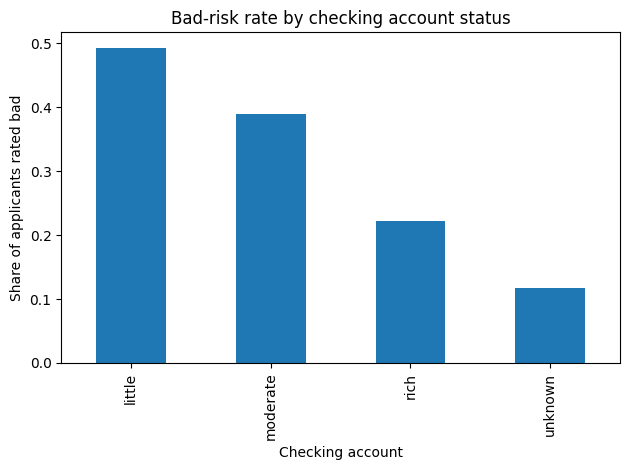

In [5]:
eda = df.copy()
eda["bad"] = y

# Bad-risk rate by checking account status (compare with the Tableau dashboard)
rate = eda.groupby("Checking account")["bad"].agg(["mean", "count"]).sort_values("mean", ascending=False)
print(rate)

rate["mean"].plot(kind="bar", title="Bad-risk rate by checking account status")
plt.ylabel("Share of applicants rated bad")
plt.tight_layout()
plt.show()

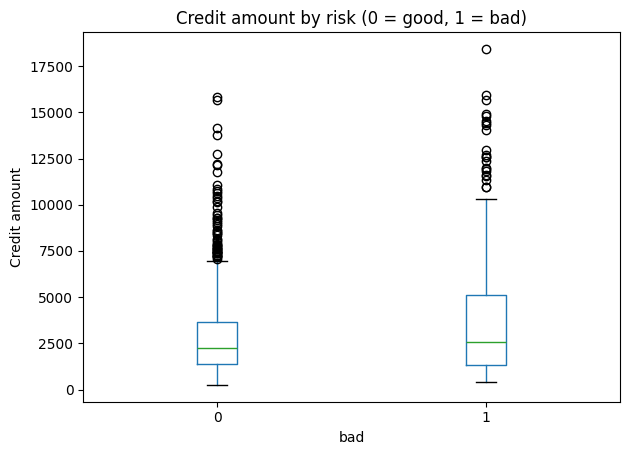

In [6]:
eda.boxplot(column="Credit amount", by="bad", grid=False)
plt.title("Credit amount by risk (0 = good, 1 = bad)")
plt.suptitle("")
plt.ylabel("Credit amount")
plt.tight_layout()
plt.show()

## 4. Prepare features

**Fairness choice:** I leave out `Sex`. Using it to score people for credit is ethically and often legally problematic, and a model validation team would flag it. I keep `Age` for now, but it is also sensitive and should be discussed in the write-up (try the model without it and note any change in results).

In [7]:
DROP = ["Sex"]
X = df.drop(columns=[TARGET] + [c for c in DROP if c in df.columns])
X = pd.get_dummies(X, drop_first=True)          # turn categories into 0/1 columns
print(X.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

(1000, 20)
Train: (750, 20)  Test: (250, 20)


## 5. Train the models
Three models: a baseline that always predicts the majority class, a logistic regression, and a shallow decision tree. `class_weight="balanced"` stops the models from ignoring the smaller *bad* group.

In [8]:
models = {
    "Baseline (always 'good')": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": Pipeline([
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    "Decision tree (depth 4)": DecisionTreeClassifier(
        max_depth=4, class_weight="balanced", random_state=RANDOM_STATE),
}
for m in models.values():
    m.fit(X_train, y_train)

## 6. Validate on the held-out test set
Accuracy alone is misleading here: a model that says "good" for everyone is already right about 70% of the time. For credit risk, **recall on the bad class** (how many risky applicants the model catches) and **precision** (how many flagged applicants were really risky) matter more.

In [9]:
rows = []
for name, m in models.items():
    pred = m.predict(X_test)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (bad)": precision_score(y_test, pred, zero_division=0),
        "Recall (bad)": recall_score(y_test, pred, zero_division=0),
        "F1 (bad)": f1_score(y_test, pred, zero_division=0),
    })
results = pd.DataFrame(rows).set_index("Model").round(3)
results

,Accuracy,Precision (bad),Recall (bad),F1 (bad)
Model,,,,
Baseline (always 'good'),0.700,0.000,0.00,0.000
Logistic regression,0.688,0.486,0.72,0.581
Decision tree (depth 4),0.656,0.456,0.76,0.570


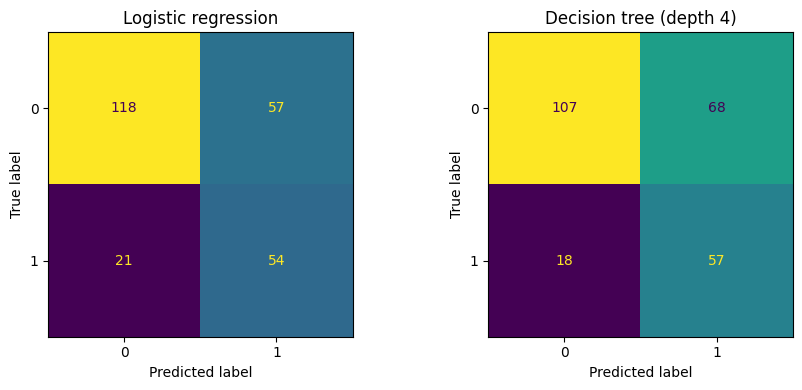

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, name in zip(axes, ["Logistic regression", "Decision tree (depth 4)"]):
    ConfusionMatrixDisplay.from_estimator(models[name], X_test, y_test, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 7. Interpret the models: which features drive the prediction?

In [11]:
logit = models["Logistic regression"].named_steps["clf"]
coefs = pd.Series(logit.coef_[0], index=X.columns).sort_values(key=abs, ascending=False)
print("Top logistic-regression drivers (positive = higher bad-risk):")
print(coefs.head(8).round(3))

tree = models["Decision tree (depth 4)"]
imp = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nTop decision-tree features:")
print(imp.head(8).round(3))

Top logistic-regression drivers (positive = higher bad-risk):
Checking account_unknown   -0.842
Duration                    0.401
Saving accounts_unknown    -0.362
Saving accounts_rich       -0.267
Purpose_education           0.215
Purpose_radio/TV           -0.167
Checking account_rich      -0.163
Housing_own                -0.151
dtype: float64

Top decision-tree features:
Checking account_unknown    0.457
Credit amount               0.220
Duration                    0.133
Age                         0.068
Saving accounts_unknown     0.046
Housing_own                 0.031
Purpose_repairs             0.025
Job                         0.019
dtype: float64


In [12]:
# Retrain the logistic regression without Age and compare
X_noage = X.drop(columns=["Age"])
Xtr, Xte, ytr, yte = train_test_split(
    X_noage, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

m = Pipeline([("scale", StandardScaler()),
              ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))])
m.fit(Xtr, ytr)
pred = m.predict(Xte)

print("Accuracy:", round(accuracy_score(yte, pred), 3))
print("Precision (bad):", round(precision_score(yte, pred), 3))
print("Recall (bad):", round(recall_score(yte, pred), 3))

Accuracy: 0.684
Precision (bad): 0.481
Recall (bad): 0.693


## 8. Findings

- **Data:** 1,000 applicants, about 30% labelled bad risk.
- **Baseline:** always predicting "good" gives 70% accuracy but catches 0% of bad applicants.
- **Best model:** neither model wins on every measure. Logistic regression: recall 0.72, precision 0.49, F1 0.58. Decision tree: recall 0.76, precision 0.46, F1 0.57. The tree catches slightly more risky applicants but raises more false alarms. Both models catch far more bad applicants than the baseline, even though their accuracy (0.69 and 0.66) is a little below the baseline's 0.70, which shows why accuracy alone is misleading here.
- **Main drivers:** applicants with no checking account on file ("unknown") have a much lower bad-risk rate (about 12%, against about 49% for "little"), and longer loan duration raises risk. Credit amount also matters in the tree. This differs from my earlier Tableau dashboard, where I grouped "little" and "NA" together as "weak checking": the labels show these groups behave in opposite ways.
- **Fairness choice:** Sex excluded. Age kept in the main models. Retraining the logistic regression without Age changed recall from 0.72 to 0.69 and precision from 0.49 to 0.48, a small change on a test set with about 75 bad applicants, so Age adds little.